In [38]:
import pandas as pd
import time
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

# 1. Load and prepare data from ARFF file
data, meta = arff.loadarff('Dry_Bean_Dataset.arff')
df = pd.DataFrame(data)

In [39]:
# Reload the data from the original source to avoid empty dataframe issues
data, meta = arff.loadarff('Dry_Bean_Dataset.arff')
df = pd.DataFrame(data)

# Safely decode string columns from bytes to utf-8 string
for col in df.columns:
    if df[col].dtype == object:
        df[col] = df[col].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else str(x))

# Separate features and target variable
X = df.iloc[:, :-1]
y = LabelEncoder().fit_transform(df.iloc[:, -1])

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Number of samples in training set:", X_train.shape[0])
print("Number of unique classes in y_train:", len(set(y_train)))

Number of samples in training set: 10888
Number of unique classes in y_train: 7


In [40]:
# Calculate and explain training and test ratios
total_samples = len(df)
train_samples = len(X_train)
test_samples = len(X_test)

train_percent = (train_samples / total_samples) * 100
test_percent = (test_samples / total_samples) * 100

print("=" * 50)
print("📊 Data Division Details (Train / Test Split):")
print("=" * 50)
print(f"🔹 Training ratio (Train Size): {train_percent:.1f}% ({train_samples:,} samples)")
print(f"🔸 Test ratio (Test Size)  : {test_percent:.1f}% ({test_samples:,} samples)")
print(f"🔹 Average sample : 100% ({total_samples:,} samples)")
print("=" * 50)

📊 Data Division Details (Train / Test Split):
🔹 Training ratio (Train Size): 80.0% (10,888 samples)
🔸 Test ratio (Test Size)  : 20.0% (2,723 samples)
🔹 Average sample : 100% (13,611 samples)


In [41]:
# 2. Random Forest Model
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_time = time.time() - t0
rf_pred = rf.predict(X_test)

# Verify Random Forest execution
print("=" * 50)
print("🎉 Random Forest Model trained successfully!")
print("=" * 50)
print(f"⏱️ Training Time: {rf_time:.3f} seconds")
print(f"🎯 Number of predictions generated: {len(rf_pred):,} predictions")
print(f"📊 First 10 predictions of the model: {rf_pred[:10]}")
print("=" * 50)

🎉 Random Forest Model trained successfully!
⏱️ Training Time: 10.811 seconds
🎯 Number of predictions generated: 2,723 predictions
📊 First 10 predictions of the model: [3 1 6 5 0 5 3 6 2 4]


In [44]:
# 3. SGDClassifier (Stochastic Gradient Descent) Model
t0 = time.time()
sgd_model = SGDClassifier(
    loss='log_loss',
    learning_rate='optimal',
    max_iter=1000,
    random_state=42
)

sgd_model.fit(X_train_scaled, y_train)
sgd_time = time.time() - t0
sgd_pred = sgd_model.predict(X_test_scaled)

print("SGD Classifier trained successfully!")
print("Time spent:", round(sgd_time, 3), "seconds")

SGD Classifier trained successfully!
Time spent: 0.509 seconds


In [42]:
# 4. Model Comparison
comparison = pd.DataFrame({
    "Model": ["Random Forest", "SGD Classifier"],
    "Accuracy": [accuracy_score(y_test, rf_pred), accuracy_score(y_test, sgd_pred)],
    "Macro F1": [f1_score(y_test, rf_pred, average='macro'), f1_score(y_test, sgd_pred, average='macro')],
    "Training Time (s)": [round(rf_time, 3), round(sgd_time, 3)]
})
display(comparison)

,Model,Accuracy,Macro F1,Training Time (s)
0,Random Forest,0.919941,0.932108,10.811
1,SGD Classifier,0.914800,0.928296,1.496


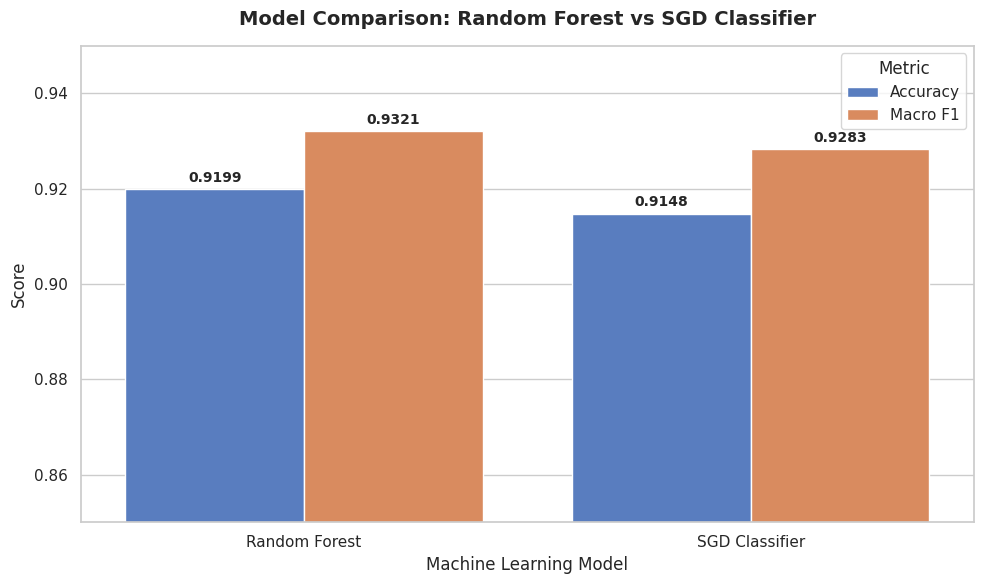

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
comparison_melted = comparison.melt(id_vars="Model", value_vars=["Accuracy", "Macro F1"],
                                     var_name="Metric", value_name="Score")

# Configure plot layout
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Draw comparison bars
ax = sns.barplot(x="Model", y="Score", hue="Metric", data=comparison_melted, palette="muted")

# Add title and labels
plt.title("Model Comparison: Random Forest vs SGD Classifier", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.ylim(0.85, 0.95)  # Set limit to show minor differences clearly

# Add data values on top of the bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.4f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()